# Chapter 6 · OCR and documents

*Book 27 · Deep Learning on Images & Signals · Shelf VII*

**Builds on:** [Chapter 4](04-detection.ipynb) (detection, and where the QR code fails) and
[Chapter 5](05-cnns-on-images.ipynb) (CNNs).
**You will:** run a modern OCR pipeline, measure its character errors per photo quality, use
check digits to catch and repair a misread, and pull structured fields out of loose text lines.

**OCR** (optical character recognition) is two networks in a row: a *detector* that finds
where text is, and a *recogniser* that reads each found line. RapidOCR runs the PP-OCRv4 pair
(plus a small classifier that flips upside-down lines) through ONNX on the CPU; the models ship
inside the Python package, so nothing is downloaded.

In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from rapidocr_onnxruntime import RapidOCR

from ds_toolbox import qrbills as qb
from ds_toolbox import viz

viz.use_style()
engine = RapidOCR()
bills = qb.generate_bills(5, seed=66)

## Boxes, then text

0.99  Receipt
0.99  Paymentpart
0.99  Account/Payableto
1.00  CH2931884926607684986
0.99  Account/Payableto
0.95  Rigi Gartenbau GmbH
0.95  5000 Aarau
0.98  CH2931884926607684986


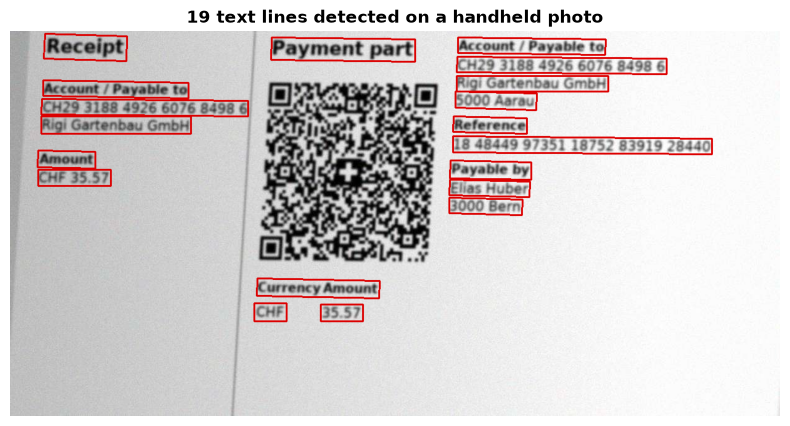

In [2]:
photo = qb.distort(qb.render(bills[0]), 2, seed=1)
result, _ = engine(photo)
shown = photo.copy()
for box, _text, _conf in result:
    cv2.polylines(shown, [np.array(box, dtype=np.int32)], True, (220, 0, 0), 2)
plt.figure(figsize=(10, 5))
plt.imshow(shown)
plt.axis("off")
plt.title(f"{len(result)} text lines detected on a handheld photo")
for _box, text, conf in result[:8]:
    print(f"{conf:.2f}  {text}")

The recogniser drops some spaces ("Payableto") and the umlaut in "Zürich" may come back as
"Zurich" -- the errors a reader of OCR output has to expect.

## Character errors per photo quality

The **character error rate** (CER) is the edit distance between what was read and what is
printed, divided by the length of the truth: insertions, deletions and substitutions all count.
Measured on the IBAN line of five bills at every quality.

In [3]:
def edit_distance(a: str, b: str) -> int:
    prev = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        cur = [i]
        for j, cb in enumerate(b, 1):
            cur.append(min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (ca != cb)))
        prev = cur
    return prev[-1]

rows, transcripts = [], {}
for k, b in enumerate(bills):
    clean = qb.render(b)
    for level in qb.QUALITY_LEVELS:
        lines = qb.ocr_lines(qb.distort(clean, level, seed=10 * k + level))
        transcripts[(k, level)] = lines
        compact = [ln.replace(" ", "").upper() for ln in qb.line_texts(lines)]
        best = min(compact, key=lambda c: edit_distance(c, b.iban)) if compact else ""
        rows.append({"level": level, "cer": edit_distance(best, b.iban) / len(b.iban), "lines": len(lines)})
cer = pd.DataFrame(rows).groupby("level").mean()
cer.index = [f"{k} · {qb.QUALITY_LEVELS[k]}" for k in cer.index]
cer.round(3)

,cer,lines
0 · flat scan,0.000,19.0
1 · good photo,0.000,19.0
2 · handheld photo,0.000,18.8
3 · far and blurred,0.029,17.2
4 · unreadable,0.752,3.2


## Check digits: catching a misread

Swiss payment data protects itself. An IBAN carries two check digits (mod 97 over the whole
number); a QR reference ends in a mod-10 recursive digit. A single misread digit almost always
breaks the check -- so a reader can *know* it misread, and often repair it: try the characters
OCR typically confuses (0/8, 1/7, 5/6, ...) and keep the one candidate that passes.

In [4]:
good = bills[0].iban
i = next(i for i in range(4, len(good)) if good[i] in qb.CONFUSIONS)
misread = good[:i] + qb.CONFUSIONS[good[i]][0] + good[i + 1:]       # one realistic confusion
print("printed:", good, "valid:", qb.iban_valid(good))
print("misread:", misread, "valid:", qb.iban_valid(misread))
print("repaired:", qb.repair(misread, qb.iban_valid), "-> matches:", qb.repair(misread, qb.iban_valid) == good)

printed: CH2931884926607684986 valid: True
misread: CH2981884926607684986 valid: False
repaired: CH2931884926607684986 -> matches: True


The repair is deliberately cautious: it accepts a fix only when **exactly one** single-character
confusion passes the check. Two candidates means the evidence cannot decide, and a wrong IBAN on
a payment is worse than no IBAN.

## How safe is the repair? Measure it

A repair can be *wrong*: change a different digit and land, by chance, on another number that
passes the check. Whether that happens depends on the **confusion table**. The first version of
this book's table was one-way -- it tried an 8 as a 0 or a 3, but never as a 6 -- so when OCR had
read a 6 as an 8, the true digit was not even among the candidates, and sometimes a wrong one
passed. Simulated on 2 000 IBANs, one realistic misread each:

In [5]:
rng = np.random.default_rng(0)
one_way = {"0": "86", "8": "03", "1": "7", "7": "1", "5": "6", "6": "50", "3": "8", "9": "4", "4": "9"}


def trial(table, field, valid, start):
    out = {"right": 0, "wrong": 0, "refused": 0}
    for b in qb.generate_bills(2000, seed=1):
        true = getattr(b, field)
        i = rng.choice([i for i in range(start, len(true)) if true[i] in qb.CONFUSIONS])
        alts = qb.CONFUSIONS[true[i]]
        bad = true[:i] + alts[rng.integers(len(alts))] + true[i + 1:]
        cands = [bad[:j] + a + bad[j + 1:] for j, c in enumerate(bad) for a in table.get(c, "")
                 if valid(bad[:j] + a + bad[j + 1:])]
        out["refused" if len(cands) != 1 else "right" if cands[0] == true else "wrong"] += 1
    return {k: f"{v / 2000:.1%}" for k, v in out.items()}


pd.DataFrame({"IBAN, one-way table": trial(one_way, "iban", qb.iban_valid, 4),
              "IBAN, symmetric table": trial(qb.CONFUSIONS, "iban", qb.iban_valid, 4),
              "reference, symmetric table": trial(qb.CONFUSIONS, "reference", qb.reference_valid, 0)}).T

,right,wrong,refused
"IBAN, one-way table",70.7%,2.4%,27.0%
"IBAN, symmetric table",84.6%,0.0%,15.4%
"reference, symmetric table",0.4%,0.0%,99.6%


The one-way table repaired 2.4 % of the IBANs *wrongly*: a valid-looking IBAN that is not the
one printed. Made symmetric, none of the 2 000 was wrong, and about a sixth were refused because
two candidates passed. The reference's single mod-10 digit carries far less information: nearly
every misread leaves several candidates that pass, so the repair refuses almost always -- the
right answer. A check digit always *verifies*; whether it can also *repair* depends on how much it
carries, and on a confusion table that contains the true mistake.

## From lines to fields

OCR returns loose lines. `extract_by_rules` turns them into the five payment fields with
patterns (a Swiss IBAN, a run of 27 digits, an amount with two decimals), the check-digit repair,
and the layout: lines in the receipt strip (x below 0.27) are ignored, and the creditor's name and
city follow the IBAN.

In [6]:
field_rows = []
for (k, level), lines in transcripts.items():
    got = qb.extract_by_rules(lines)
    for field, ok in qb.score_fields(got, bills[k].fields()).items():
        field_rows.append({"level": level, "field": field, "correct": ok})
fields = pd.DataFrame(field_rows).pivot_table(index="field", columns="level", values="correct", aggfunc="mean")
fields = fields.reindex(list(qb.FIELDS))
(fields * 100).round(0)

level,0,1,2,3,4
field,,,,,
iban,100.0,100.0,100.0,40.0,0.0
amount,100.0,100.0,100.0,100.0,0.0
reference,100.0,100.0,100.0,60.0,0.0
creditor_name,80.0,80.0,80.0,40.0,0.0
creditor_city,80.0,80.0,80.0,20.0,0.0


Two kinds of error remain, and they need different cures. Digits that OCR misreads beyond one
confusion cannot be repaired by any rule. Names and places that OCR reads *almost* right --
"Zurich", "MusterAG" -- fail an exact comparison although a person would read them correctly.
The challenge asks whether a language model, told the same rules about check digits, closes the
second gap without opening new ones.

## What to remember

- OCR is detection, then recognition. Expect dropped spaces and lost accents.
- Measure with the character error rate, per quality.
- Check digits turn "probably right" into "verified" -- and make cautious repair possible.

## Exercises

1. Compute the CER on the reference line instead of the IBAN. Is it higher or lower, and why?
2. Make `repair` accept the first passing candidate instead of the only one. How often is it wrong?
3. Normalise "Zurich" to "Zürich" with a list of Swiss place names. How much of the city gap closes?

**Next:** [The challenge · qr-bill-reader](challenge/qr-bill-reader.ipynb)